In [1]:
import pandas as pd

phish_df = pd.read_csv("../data/raw/phishtank.csv")

print("Shape:", phish_df.shape)
phish_df.head()

Shape: (73267, 8)


,phish_id,url,phish_detail_url,submission_time,verified,verification_time,online,target
0,9510202,https://processesene.dressel-garten.de/f069d79...,http://www.phishtank.com/phish_detail.php?phis...,2026-08-24T13:58:50+00:00,yes,2026-08-24T14:03:07+00:00,yes,Other
1,9510198,https://bhdactivarusuario2026.weebly.com/,http://www.phishtank.com/phish_detail.php?phis...,2026-08-24T13:52:12+00:00,yes,2026-08-24T14:03:07+00:00,yes,Other
2,9510197,https://validaracceso-bhdactivarusuario.iceiy.com,http://www.phishtank.com/phish_detail.php?phis...,2026-08-24T13:51:51+00:00,yes,2026-08-24T14:03:07+00:00,yes,Other
3,9510195,https://encuestaecuador.lat/3gKhsRHNWn?adset_n...,http://www.phishtank.com/phish_detail.php?phis...,2026-08-24T13:51:35+00:00,yes,2026-08-24T14:03:07+00:00,yes,Other
4,9510187,https://cliente-a-limpfeirao.shop/,http://www.phishtank.com/phish_detail.php?phis...,2026-08-24T13:42:29+00:00,yes,2026-08-24T13:46:12+00:00,yes,Other


In [2]:
phish_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 73267 entries, 0 to 73266
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   phish_id           73267 non-null  int64
 1   url                73267 non-null  str  
 2   phish_detail_url   73267 non-null  str  
 3   submission_time    73267 non-null  str  
 4   verified           73267 non-null  str  
 5   verification_time  73267 non-null  str  
 6   online             73267 non-null  str  
 7   target             73267 non-null  str  
dtypes: int64(1), str(7)
memory usage: 4.5 MB


In [3]:
phish_df.columns

Index(['phish_id', 'url', 'phish_detail_url', 'submission_time', 'verified',
       'verification_time', 'online', 'target'],
      dtype='str')

In [4]:
phish_df.isnull().sum()

phish_id             0
url                  0
phish_detail_url     0
submission_time      0
verified             0
verification_time    0
online               0
target               0
dtype: int64

In [5]:
phish_df["online"].value_counts()

online
yes    73267
Name: count, dtype: int64

In [6]:
phish_df["verified"].value_counts()

verified
yes    73267
Name: count, dtype: int64

In [7]:
print("Duplicate URLs:", phish_df["url"].duplicated().sum())

Duplicate URLs: 3


In [8]:
print("Unique URLs:", phish_df["url"].nunique())

Unique URLs: 73264


In [9]:
phish_df["target"].value_counts().head(20)

target
Other                                  65277
Allegro                                 3566
Internal Revenue Service                 880
Amazon.com                               600
Facebook                                 411
Microsoft                                374
Bradesco                                 236
Netflix                                  220
Optus                                    151
SociÃ©tÃ© GÃ©nÃ©rale                     146
Comcast                                  124
PayPal                                   102
Sumitomo Mitsui Banking Corporation       74
Adobe                                     71
Google                                    69
AT&amp;T                                  66
American Express                          66
Apple                                     61
DocuSign                                  60
DHL                                       49
Name: count, dtype: int64

In [10]:
phish_df = phish_df[
    (phish_df["verified"] == "yes") &
    (phish_df["online"] == "yes")
]

phish_df = phish_df.drop_duplicates(subset="url")

In [11]:
print("Empty URLs:", (phish_df["url"].str.strip() == "").sum())

Empty URLs: 0


In [12]:
print(phish_df["url"].head(10).to_string(index=False))

https://processesene.dressel-garten.de/f069d796...
         https://bhdactivarusuario2026.weebly.com/
 https://validaracceso-bhdactivarusuario.iceiy.com
https://encuestaecuador.lat/3gKhsRHNWn?adset_na...
                https://cliente-a-limpfeirao.shop/
              http://www.cliente-a-limpfeirao.shop
https://security-server-page--hollywoodcoache.r...
https://secure-site-manager--type4life.replit.app/
   https://secure-static-site--dgtoney.replit.app/
https://lndosnr743.shop/o/rsswb/732182999258316...


In [13]:
print(phish_df["url"].str[:20].value_counts().head(20))

url
https://docs.google.    5726
http://allegrolokaln    1219
https://sites.google    1140
https://new.express.    1069
https://allegrolokal     735
https://www.dropbox.     622
https://l.wl.co/l?u=     483
https://l.ead.me/bgb     471
https://l.ead.me/bga     375
https://tinyurl.com/     344
https://l.ead.me/bfJ     256
http://allegro-lokal     255
https://klelnanzeige     243
https://kleinanzeige     239
https://ipfs.best-pr     232
https://eu.jotform.c     216
https://l.ead.me/bfI     205
https://l.ead.me/bgc     184
https://qr-codes.io/     173
https://app.jotform.     165
Name: count, dtype: int64


In [14]:
phish_clean = phish_df[
    (phish_df["verified"] == "yes") &
    (phish_df["online"] == "yes")
].copy()

phish_clean = phish_clean.drop_duplicates(subset="url")

phish_clean = phish_clean[["url"]]

phish_clean["label"] = 1

In [15]:
tranco_df = pd.read_csv(
    "../data/raw/tranco.csv",
    header=None,
    names=["rank", "domain"]
)

print("Shape:", tranco_df.shape)
tranco_df.head()

Shape: (1000000, 2)


,rank,domain
0,1,google.com
1,2,cloudflare.com
2,3,facebook.com
3,4,gstatic.com
4,5,googleapis.com


In [16]:
tranco_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 2 columns):
 #   Column  Non-Null Count    Dtype
---  ------  --------------    -----
 0   rank    1000000 non-null  int64
 1   domain  1000000 non-null  str  
dtypes: int64(1), str(1)
memory usage: 15.3 MB


In [17]:
print("Duplicate domains:", tranco_df["domain"].duplicated().sum())
print("Unique domains:", tranco_df["domain"].nunique())

Duplicate domains: 0
Unique domains: 1000000


In [18]:
from urllib.parse import urlparse

# Extract hostname from phishing URLs
phish_domains = (
    phish_df["url"]
    .apply(lambda x: urlparse(x).netloc.lower().replace("www.", ""))
)

# Normalize Tranco domains
tranco_domains = (
    tranco_df["domain"]
    .str.lower()
    .str.strip()
    .str.replace(r"\.$", "", regex=True)
)

overlap = set(phish_domains) & set(tranco_domains)

print("Phishing domains:", len(set(phish_domains)))
print("Tranco domains:", len(set(tranco_domains)))
print("Overlapping domains:", len(overlap))

Phishing domains: 38429
Tranco domains: 1000000
Overlapping domains: 317


In [19]:
tranco_clean = tranco_df[
    ~tranco_domains.isin(overlap)
].copy()

print("Original Tranco domains:", len(tranco_df))
print("Removed overlapping domains:", len(overlap))
print("Remaining domains:", len(tranco_clean))

Original Tranco domains: 1000000
Removed overlapping domains: 317
Remaining domains: 999683


In [20]:
tranco_clean.head()

,rank,domain
1,2,cloudflare.com
2,3,facebook.com
3,4,gstatic.com
4,5,googleapis.com
5,6,microsoft.com


In [21]:
legit_candidates = tranco_clean.head(60000).copy()

legit_candidates["url"] = "https://" + legit_candidates["domain"]

print("Candidate URLs:", len(legit_candidates))
legit_candidates.head()

Candidate URLs: 60000


,rank,domain,url
1,2,cloudflare.com,https://cloudflare.com
2,3,facebook.com,https://facebook.com
3,4,gstatic.com,https://gstatic.com
4,5,googleapis.com,https://googleapis.com
5,6,microsoft.com,https://microsoft.com


In [22]:
test_candidates = legit_candidates.head(500).copy()

test_candidates["url"].head()

1    https://cloudflare.com
2      https://facebook.com
3       https://gstatic.com
4    https://googleapis.com
5     https://microsoft.com
Name: url, dtype: str

In [23]:
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed

def check_url(url):
    try:
        response = requests.get(
            url,
            timeout=5,
            allow_redirects=True,
            headers={"User-Agent": "Mozilla/5.0"}
        )

        return {
            "url": url,
            "active": response.status_code < 500,
            "status_code": response.status_code,
            "error": None
        }

    except requests.RequestException as e:
        return {
            "url": url,
            "active": False,
            "status_code": None,
            "error": type(e).__name__
        }

In [24]:
results = []

with ThreadPoolExecutor(max_workers=10) as executor:
    futures = [
        executor.submit(check_url, url)
        for url in test_candidates["url"]
    ]

    for i, future in enumerate(as_completed(futures), 1):
        results.append(future.result())

        if i % 50 == 0:
            print(f"Checked {i}/500")

legit_status = pd.DataFrame(results)

print("Total checked:", len(legit_status))
print("Active:", legit_status["active"].sum())
print("Inactive:", (~legit_status["active"]).sum())

Checked 50/500
Checked 100/500
Checked 150/500
Checked 200/500
Checked 250/500
Checked 300/500
Checked 350/500
Checked 400/500
Checked 450/500
Checked 500/500
Total checked: 500
Active: 314
Inactive: 186


In [25]:
print(
    legit_status["status_code"]
    .value_counts(dropna=False)
)

status_code
200.0    229
NaN      185
403.0     58
404.0     13
202.0      7
401.0      3
400.0      1
418.0      1
429.0      1
498.0      1
503.0      1
Name: count, dtype: int64


In [26]:
legit_status["reachable"] = legit_status["status_code"].notna()

print(legit_status["reachable"].value_counts())

reachable
True     315
False    185
Name: count, dtype: int64


In [27]:
legit_reachable = legit_status[
    legit_status["reachable"]
].copy()

print("Reachable legitimate domains:", len(legit_reachable))

Reachable legitimate domains: 315


In [28]:
print(
    legit_reachable["status_code"]
    .value_counts()
)

status_code
200.0    229
403.0     58
404.0     13
202.0      7
401.0      3
400.0      1
418.0      1
429.0      1
498.0      1
503.0      1
Name: count, dtype: int64


In [29]:
legit_reachable["label"] = 0

In [30]:
legit_reachable[["url", "label"]].to_csv(
    "../data/processed/legitimate_validated.csv",
    index=False
)

In [31]:
print(legit_reachable[["url", "label"]].head())
print(legit_reachable["label"].value_counts())

                      url  label
0  https://googleapis.com      0
3       https://apple.com      0
4     https://gstatic.com      0
5   https://microsoft.com      0
6  https://cloudflare.com      0
label
0    315
Name: count, dtype: int64


In [32]:
phish_df["label"] = 1

print(phish_df[["url", "label"]].head())
print(phish_df["label"].value_counts())

                                                 url  label
0  https://processesene.dressel-garten.de/f069d79...      1
1          https://bhdactivarusuario2026.weebly.com/      1
2  https://validaracceso-bhdactivarusuario.iceiy.com      1
3  https://encuestaecuador.lat/3gKhsRHNWn?adset_n...      1
4                 https://cliente-a-limpfeirao.shop/      1
label
1    73264
Name: count, dtype: int64


In [33]:
print("Phishing URLs:", len(phish_df))
print("Unique phishing URLs:", phish_df["url"].nunique())
print("Duplicate phishing URLs:", phish_df["url"].duplicated().sum())

Phishing URLs: 73264
Unique phishing URLs: 73264
Duplicate phishing URLs: 0


In [34]:
phish_df = phish_df.drop_duplicates(subset="url").copy()

print("Phishing URLs:", len(phish_df))
print("Unique phishing URLs:", phish_df["url"].nunique())

Phishing URLs: 73264
Unique phishing URLs: 73264


In [35]:
overlap = set(phish_df["url"]) & set(legit_reachable["url"])

print("Exact URL overlap:", len(overlap))

Exact URL overlap: 0


In [36]:
legit_final = legit_reachable[["url", "label"]].copy()
phish_final = phish_df[["url", "label"]].copy()

dataset = pd.concat(
    [legit_final, phish_final],
    ignore_index=True
)

print("Final dataset shape:", dataset.shape)
print(dataset["label"].value_counts())

Final dataset shape: (73579, 2)
label
1    73264
0      315
Name: count, dtype: int64


In [37]:
legit_sample = tranco_df.sample(
    n=30000,
    random_state=42
).copy()

legit_sample["url"] = "https://" + legit_sample["domain"]

print("Candidate URLs:", len(legit_sample))
print(legit_sample.head())

Candidate URLs: 30000
          rank              domain                         url
987231  987232  inspections.gov.ua  https://inspections.gov.ua
79954    79955         babechat.ai         https://babechat.ai
567130  567131  alphaluckyworld.nl  https://alphaluckyworld.nl
500891  500892            dxzq.net            https://dxzq.net
55399    55400    memorialcare.org    https://memorialcare.org


In [38]:
phish_domains = set(
    phish_df["url"]
    .str.extract(r"https?://([^/]+)")[0]
    .str.lower()
)

legit_sample = legit_sample[
    ~legit_sample["domain"].str.lower().isin(phish_domains)
].copy()

print("After overlap removal:", len(legit_sample))

After overlap removal: 29994


In [39]:
test_sample = legit_sample.head(1000).copy()

print("Testing:", len(test_sample))

Testing: 1000


In [40]:
import requests
import pandas as pd
from concurrent.futures import ThreadPoolExecutor, as_completed

def check_url(url):
    try:
        response = requests.get(
            url,
            timeout=5,
            headers={
                "User-Agent": "Mozilla/5.0"
            },
            allow_redirects=True
        )

        return {
            "url": url,
            "status_code": response.status_code,
            "final_url": response.url
        }

    except requests.RequestException:
        return {
            "url": url,
            "status_code": None,
            "final_url": None
        }


results = []

with ThreadPoolExecutor(max_workers=20) as executor:

    futures = [
        executor.submit(check_url, url)
        for url in test_sample["url"]
    ]

    for i, future in enumerate(as_completed(futures), 1):

        results.append(future.result())

        if i % 50 == 0:
            print(f"Checked {i}/{len(futures)}")


test_status = pd.DataFrame(results)

print("\nTotal checked:", len(test_status))
print(
    "Responded:",
    test_status["status_code"].notna().sum()
)
print(
    "No response:",
    test_status["status_code"].isna().sum()
)

Checked 50/1000
Checked 100/1000
Checked 150/1000
Checked 200/1000
Checked 250/1000
Checked 300/1000
Checked 350/1000
Checked 400/1000
Checked 450/1000
Checked 500/1000
Checked 550/1000
Checked 600/1000
Checked 650/1000
Checked 700/1000
Checked 750/1000
Checked 800/1000
Checked 850/1000
Checked 900/1000
Checked 950/1000
Checked 1000/1000

Total checked: 1000
Responded: 758
No response: 242


In [41]:
print(
    test_status["status_code"]
    .value_counts(dropna=False)
)

status_code
200.0    589
NaN      242
403.0    135
404.0     11
406.0      5
500.0      4
503.0      3
401.0      2
202.0      2
525.0      1
468.0      1
521.0      1
502.0      1
520.0      1
429.0      1
523.0      1
Name: count, dtype: int64


In [42]:
print(
    test_status[test_status["status_code"].notna()]
    ["status_code"]
    .value_counts()
)

status_code
200.0    589
403.0    135
404.0     11
406.0      5
500.0      4
503.0      3
401.0      2
202.0      2
525.0      1
468.0      1
521.0      1
502.0      1
520.0      1
429.0      1
523.0      1
Name: count, dtype: int64


In [43]:
legit_validated = test_status[
    test_status["status_code"].notna()
].copy()

legit_validated["label"] = 0

In [44]:
legit_reachable = test_status[
    test_status["status_code"].notna()
].copy()

print("Reachable legitimate URLs:", len(legit_reachable))
print(legit_reachable[["url", "status_code"]].head())

Reachable legitimate URLs: 758
                         url  status_code
2         https://mairie.biz        403.0
3       https://novolink.net        403.0
4     https://motorfloor.com        200.0
6  https://rantingtogel.live        403.0
7      https://247horses.com        403.0


In [46]:
print("legit_reachable:", len(legit_reachable))
print("phishing:", len(phish_df))

legit_reachable: 758
phishing: 73264


In [47]:
# Balance the dataset

legit_final = legit_reachable.copy()

phish_final = phish_df.sample(
    n=len(legit_final),
    random_state=42
).copy()

dataset = pd.concat(
    [legit_final, phish_final],
    ignore_index=True
)

# Shuffle the combined dataset
dataset = dataset.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Dataset shape:", dataset.shape)
print("\nClass distribution:")
print(dataset["label"].value_counts())

Dataset shape: (1516, 11)

Class distribution:
label
1.0    758
Name: count, dtype: int64


In [62]:
# Balance the dataset

# Legitimate URLs = class 0
legit_final = legit_reachable.copy()
legit_final["label"] = 0

# Phishing URLs = class 1
phish_final = phish_df.sample(
    n=len(legit_final),
    random_state=42
).copy()
phish_final["label"] = 1

# Combine both classes
dataset = pd.concat(
    [legit_final, phish_final],
    ignore_index=True
)

# Shuffle
dataset = dataset.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Dataset shape:", dataset.shape)
print("\nClass distribution:")
print(dataset["label"].value_counts())

Dataset shape: (1516, 11)

Class distribution:
label
0    758
1    758
Name: count, dtype: int64


In [63]:
dataset.head(10)

,url,status_code,final_url,label,phish_id,phish_detail_url,submission_time,verified,verification_time,online,target
0,https://suteba.org.ar,200.0,https://www.suteba.org.ar/,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,https://recoverfit.com,200.0,https://recoverfit.com/,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,https://bit.ly/2210strp5,NaN,NaN,1,8823131.0,http://www.phishtank.com/phish_detail.php?phis...,2024-10-29T12:09:32+00:00,yes,2024-10-29T12:22:26+00:00,yes,Other
3,https://q-r.to/bgbaMo,NaN,NaN,1,9339147.0,http://www.phishtank.com/phish_detail.php?phis...,2026-02-10T00:21:19+00:00,yes,2026-02-10T00:41:59+00:00,yes,Other
4,https://copyrightaid.co.uk,200.0,https://copyrightaid.co.uk/,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,https://dgpugzqswtczge.web.app/,NaN,NaN,1,9250124.0,http://www.phishtank.com/phish_detail.php?phis...,2025-10-25T10:21:42+00:00,yes,2025-10-25T10:32:39+00:00,yes,Other
6,https://889993611.xyz,200.0,https://889993611.xyz/,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,https://mybroadband.co.za,403.0,https://mybroadband.co.za/,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,https://livedesktop-enus.wixstudio.com/desktop,NaN,NaN,1,9446159.0,http://www.phishtank.com/phish_detail.php?phis...,2026-06-07T10:19:20+00:00,yes,2026-06-07T10:22:38+00:00,yes,Other
9,https://www.pcn-noticey.top/com,NaN,NaN,1,9430818.0,http://www.phishtank.com/phish_detail.php?phis...,2026-05-21T22:53:50+00:00,yes,2026-05-21T23:52:23+00:00,yes,Other


In [64]:
# FEATURE EXTRATOR

from urllib.parse import urlparse
import re
import ipaddress


def extract_url_features(url):
    parsed = urlparse(url)

    hostname = parsed.hostname or ""
    path = parsed.path or ""
    query = parsed.query or ""

    features = {}

    # Basic length features
    features["url_length"] = len(url)
    features["hostname_length"] = len(hostname)
    features["path_length"] = len(path)

    # Character counts
    features["num_dots"] = url.count(".")
    features["num_hyphens"] = url.count("-")
    features["num_slashes"] = url.count("/")
    features["num_digits"] = sum(c.isdigit() for c in url)
    features["num_special_chars"] = len(re.findall(r"[^a-zA-Z0-9]", url))

    # Protocol
    features["has_https"] = int(parsed.scheme == "https")

    # Suspicious characters
    features["has_at_symbol"] = int("@" in url)
    features["has_query"] = int(bool(query))

    # IP address instead of domain
    try:
        ipaddress.ip_address(hostname)
        features["has_ip"] = 1
    except ValueError:
        features["has_ip"] = 0

    # Subdomain count
    hostname_parts = hostname.split(".") if hostname else []

    if len(hostname_parts) > 2:
        features["num_subdomains"] = len(hostname_parts) - 2
    else:
        features["num_subdomains"] = 0

    # Suspicious keywords
    suspicious_words = [
        "login",
        "signin",
        "verify",
        "verification",
        "account",
        "update",
        "secure",
        "password",
        "bank",
        "confirm",
        "authenticate",
        "wallet",
        "payment"
    ]

    url_lower = url.lower()

    features["has_suspicious_keyword"] = int(
        any(word in url_lower for word in suspicious_words)
    )

    return features

In [65]:
extract_url_features(dataset["url"].iloc[0])

{'url_length': 21,
 'hostname_length': 13,
 'path_length': 0,
 'num_dots': 2,
 'num_hyphens': 0,
 'num_slashes': 2,
 'num_digits': 0,
 'num_special_chars': 5,
 'has_https': 1,
 'has_at_symbol': 0,
 'has_query': 0,
 'has_ip': 0,
 'num_subdomains': 1,
 'has_suspicious_keyword': 0}

In [66]:
features = dataset["url"].apply(extract_url_features)

features_df = pd.DataFrame(features.tolist())

features_df.head()

,url_length,hostname_length,path_length,num_dots,num_hyphens,num_slashes,num_digits,num_special_chars,has_https,has_at_symbol,has_query,has_ip,num_subdomains,has_suspicious_keyword
0,21,13,0,2,0,2,0,5,1,0,0,0,1,0
1,22,14,0,1,0,2,0,4,1,0,0,0,0,0
2,24,6,10,1,0,3,5,5,1,0,0,0,0,0
3,21,6,7,1,1,3,0,6,1,0,0,0,0,0
4,26,18,0,2,0,2,0,5,1,0,0,0,1,0


In [67]:
features_df["label"] = dataset["label"].values

print("Feature shape:", features_df.shape)
features_df.head()

Feature shape: (1516, 15)


,url_length,hostname_length,path_length,num_dots,num_hyphens,num_slashes,num_digits,num_special_chars,has_https,has_at_symbol,has_query,has_ip,num_subdomains,has_suspicious_keyword,label
0,21,13,0,2,0,2,0,5,1,0,0,0,1,0,0
1,22,14,0,1,0,2,0,4,1,0,0,0,0,0,0
2,24,6,10,1,0,3,5,5,1,0,0,0,0,0,1
3,21,6,7,1,1,3,0,6,1,0,0,0,0,0,1
4,26,18,0,2,0,2,0,5,1,0,0,0,1,0,0


In [68]:
# INSPECTION

print(features_df.columns.tolist())

print(features_df.describe())

print(features_df["label"].value_counts())

['url_length', 'hostname_length', 'path_length', 'num_dots', 'num_hyphens', 'num_slashes', 'num_digits', 'num_special_chars', 'has_https', 'has_at_symbol', 'has_query', 'has_ip', 'num_subdomains', 'has_suspicious_keyword', 'label']
        url_length  hostname_length  path_length     num_dots  num_hyphens  \
count  1516.000000      1516.000000  1516.000000  1516.000000  1516.000000   
mean     39.352902        17.951847     7.769789     1.536280     0.619393   
std      53.552850        10.629726    22.198276     0.778848     1.532786   
min      13.000000         4.000000     0.000000     1.000000     0.000000   
25%      21.000000        11.000000     0.000000     1.000000     0.000000   
50%      25.000000        15.000000     0.000000     1.000000     0.000000   
75%      40.000000        21.250000     7.000000     2.000000     1.000000   
max    1108.000000        76.000000   366.000000     8.000000    23.000000   

       num_slashes   num_digits  num_special_chars    has_https  

In [69]:
# Separate features and labels

X = features_df.drop("label", axis=1)
y = features_df["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1516, 14)
y shape: (1516,)


In [70]:
print("Missing labels:", y.isna().sum())
print("\nLabel distribution:")
print(y.value_counts(dropna=False))

Missing labels: 0

Label distribution:
label
0    758
1    758
Name: count, dtype: int64


In [71]:
print(features_df[features_df["label"].isna()].head())

Empty DataFrame
Columns: [url_length, hostname_length, path_length, num_dots, num_hyphens, num_slashes, num_digits, num_special_chars, has_https, has_at_symbol, has_query, has_ip, num_subdomains, has_suspicious_keyword, label]
Index: []


In [72]:
print(features_df["label"].value_counts(dropna=False))

label
0    758
1    758
Name: count, dtype: int64


In [73]:
# Fix label alignment
features_df["label"] = dataset["label"].to_numpy()

print("Missing labels:", features_df["label"].isna().sum())
print("\nLabel distribution:")
print(features_df["label"].value_counts())

Missing labels: 0

Label distribution:
label
0    758
1    758
Name: count, dtype: int64


In [74]:
print("DATASET:")
print(dataset["label"].value_counts(dropna=False))

print("\nFEATURES:")
print(features_df["label"].value_counts(dropna=False))

DATASET:
label
0    758
1    758
Name: count, dtype: int64

FEATURES:
label
0    758
1    758
Name: count, dtype: int64


In [75]:
# Train Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (1212, 14)
Testing: (304, 14)


In [76]:
# Random Forest Model

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [77]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9967105263157895

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       152
           1       1.00      0.99      1.00       152

    accuracy                           1.00       304
   macro avg       1.00      1.00      1.00       304
weighted avg       1.00      1.00      1.00       304


Confusion Matrix:
[[152   0]
 [  1 151]]


In [78]:
# Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print(feature_importance)

                   feature  importance
5              num_slashes    0.289360
2              path_length    0.276266
7        num_special_chars    0.175413
0               url_length    0.076044
12          num_subdomains    0.042659
1          hostname_length    0.042653
6               num_digits    0.033886
3                 num_dots    0.032182
8                has_https    0.014139
4              num_hyphens    0.013412
10               has_query    0.002876
13  has_suspicious_keyword    0.001110
9            has_at_symbol    0.000000
11                  has_ip    0.000000


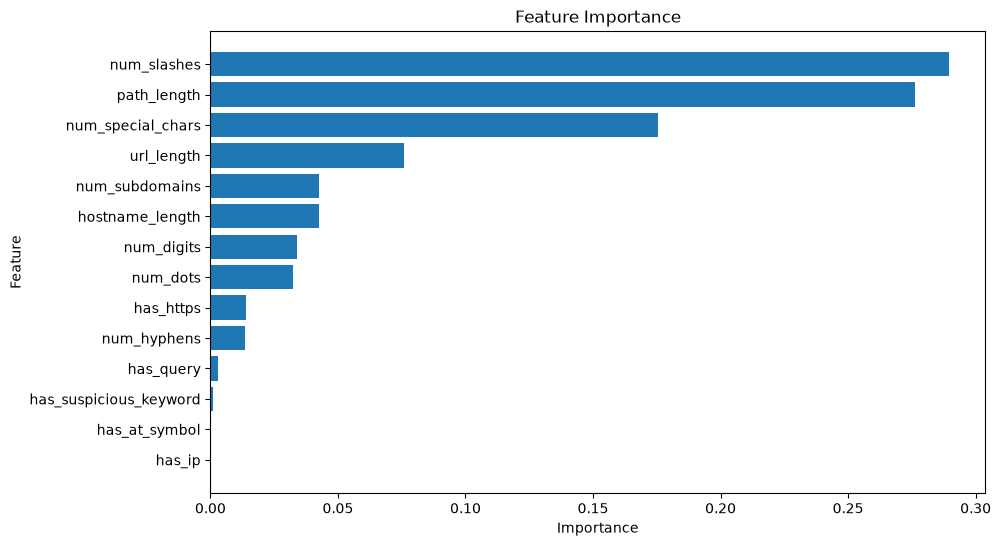

In [79]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance")

plt.gca().invert_yaxis()

plt.show()

In [80]:
print(
    features_df.groupby("label")[
        ["num_slashes", "path_length", "num_special_chars", "url_length"]
    ].mean()
)

       num_slashes  path_length  num_special_chars  url_length
label                                                         
0         2.000000     0.000000           4.218997   22.055409
1         3.505277    15.539578           8.770449   56.650396


In [81]:
print(
    features_df.groupby("label")[
        ["num_slashes", "path_length", "num_special_chars", "url_length"]
    ].median()
)

       num_slashes  path_length  num_special_chars  url_length
label                                                         
0              2.0          0.0                4.0        21.0
1              3.0          7.0                7.0        40.0


In [82]:
import shap

In [83]:
print(type(model))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [84]:
import shap

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test)

print(type(shap_values))

<class 'numpy.ndarray'>


In [85]:
print("X_test shape:", X_test.shape)
print("SHAP shape:", getattr(shap_values, "shape", "list"))

if isinstance(shap_values, list):
    print("Number of SHAP arrays:", len(shap_values))
    for i, values in enumerate(shap_values):
        print(f"Class {i} shape:", values.shape)

X_test shape: (304, 14)
SHAP shape: (304, 14, 2)


In [86]:
# SHAP values for the phishing class
shap_phishing = shap_values[:, :, 1]

print("SHAP phishing shape:", shap_phishing.shape)

SHAP phishing shape: (304, 14)


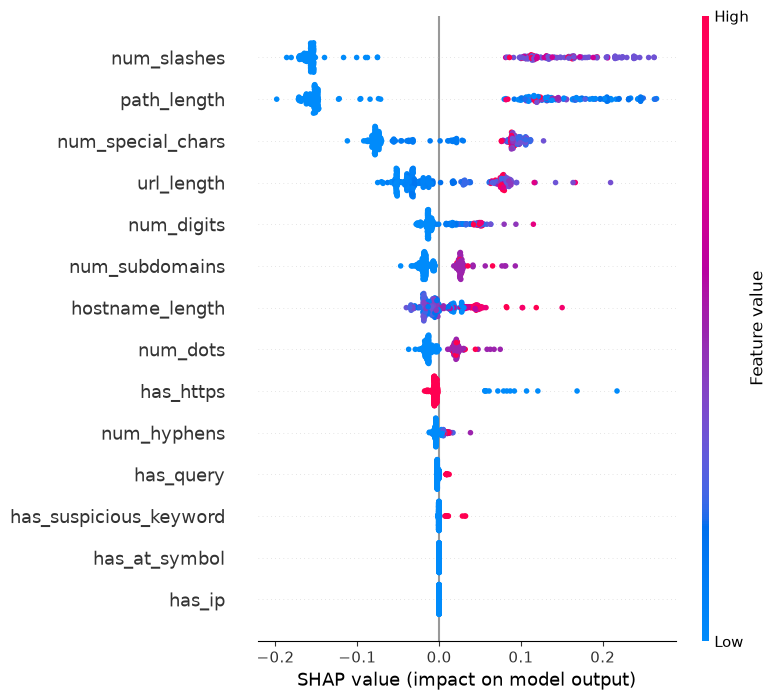

In [87]:
shap.summary_plot(
    shap_phishing,
    X_test,
    feature_names=X_test.columns
)

In [88]:
# Pick one test sample
sample_index = 0

sample = X_test.iloc[[sample_index]]

print("URL:")
print(dataset.iloc[X_test.index[sample_index]]["url"])

print("\nActual label:")
print(y_test.iloc[sample_index])

print("\nPredicted label:")
print(model.predict(sample)[0])

URL:
https://sourceready.com

Actual label:
0

Predicted label:
0


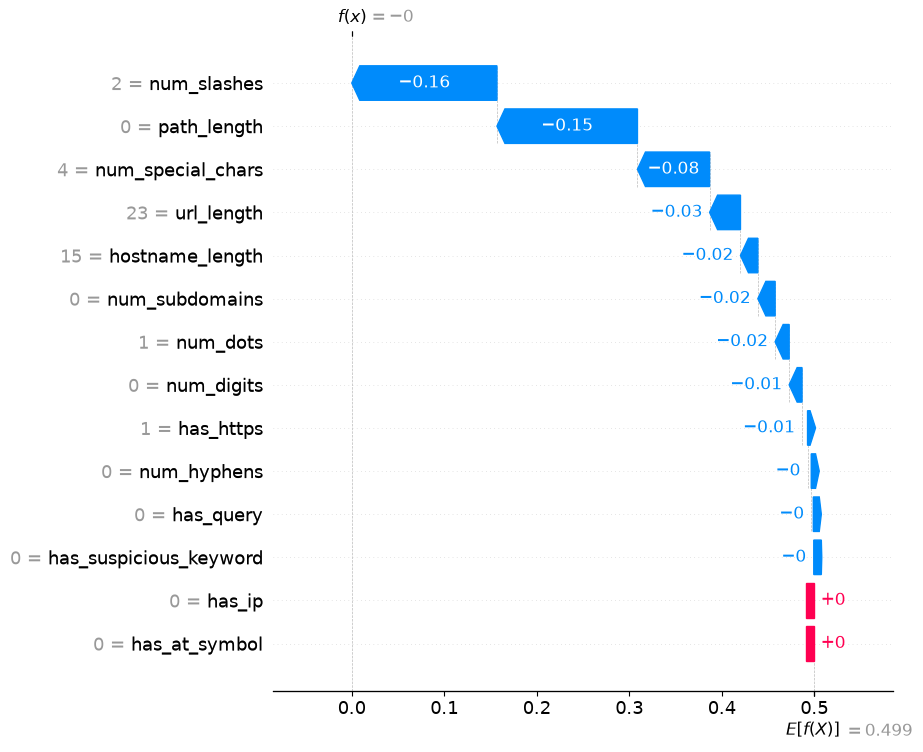

In [89]:
# SHAP explanation for this specific URL

sample_index = 0

sample = X_test.iloc[sample_index]

shap_explanation = shap.Explanation(
    values=shap_phishing[sample_index],
    base_values=explainer.expected_value[1],
    data=sample,
    feature_names=X_test.columns
)

shap.waterfall_plot(shap_explanation, max_display=14)

In [90]:
print(type(model))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [91]:
def predict_url(url):
    # Extract the same 14 features used during training
    features = extract_url_features(url)

    # Convert to DataFrame
    X_new = pd.DataFrame([features])

    # Ensure exactly the same feature order as training
    X_new = X_new[X.columns]

    # Prediction
    prediction = model.predict(X_new)[0]

    # Prediction probabilities
    probabilities = model.predict_proba(X_new)[0]

    legitimate_probability = probabilities[0]
    phishing_probability = probabilities[1]

    # Human-readable prediction
    label = "Phishing" if prediction == 1 else "Legitimate"

    print("URL:", url)
    print("Prediction:", label)
    print(f"Phishing probability: {phishing_probability:.2%}")
    print(f"Legitimate probability: {legitimate_probability:.2%}")

    return {
        "url": url,
        "prediction": int(prediction),
        "label": label,
        "phishing_probability": phishing_probability,
        "legitimate_probability": legitimate_probability,
        "features": X_new
    }

In [92]:
result = predict_url("https://sourceready.com")

URL: https://sourceready.com
Prediction: Legitimate
Phishing probability: 0.00%
Legitimate probability: 100.00%


In [96]:
test_phishing_url = phish_df["url"].iloc[0]

result = predict_url(test_phishing_url)

URL: https://processesene.dressel-garten.de/f069d796c8e0f2c046a5612bb0eeee28/AreaUtenti_Lang.php?servizio=TW96aWxsYS81LjAgKExpbnV4OyBUaXplbiA2LjUpIEFwcGxlV2ViS2l0LzUzNy4zNiAoS0hUTUwsIGxpa2UgR2Vja28pIE1vYmlsZSBUaXplbkJyb3dzZXIvNi41MTcyLjY5LjY4LjE2MjAyNjpBdWc6TW9u
Prediction: Phishing
Phishing probability: 100.00%
Legitimate probability: 0.00%


In [97]:
print(test_phishing_url)

https://processesene.dressel-garten.de/f069d796c8e0f2c046a5612bb0eeee28/AreaUtenti_Lang.php?servizio=TW96aWxsYS81LjAgKExpbnV4OyBUaXplbiA2LjUpIEFwcGxlV2ViS2l0LzUzNy4zNiAoS0hUTUwsIGxpa2UgR2Vja28pIE1vYmlsZSBUaXplbkJyb3dzZXIvNi41MTcyLjY5LjY4LjE2MjAyNjpBdWc6TW9u


In [98]:
result = predict_url(
    "https://processesene.dressel-garten.de/f069d796c8e0f2c046a5612bb0eeee28/AreaUtenti_Lang.php?servizio=TW96aWxsYS81LjAgKExpbnV4OyBUaXplbiA2LjUpIEFwcGxlV2ViS2l0LzUzNy4zNiAoS0hUTUwsIGxpa2UgR2Vja28pIE1vYmlsZSBUaXplbkJyb3dzZXIvNi41MTcyLjY5LjY4LjE2MjAyNjpBdWc6TW9u"
)

URL: https://processesene.dressel-garten.de/f069d796c8e0f2c046a5612bb0eeee28/AreaUtenti_Lang.php?servizio=TW96aWxsYS81LjAgKExpbnV4OyBUaXplbiA2LjUpIEFwcGxlV2ViS2l0LzUzNy4zNiAoS0hUTUwsIGxpa2UgR2Vja28pIE1vYmlsZSBUaXplbkJyb3dzZXIvNi41MTcyLjY5LjY4LjE2MjAyNjpBdWc6TW9u
Prediction: Phishing
Phishing probability: 100.00%
Legitimate probability: 0.00%


In [99]:
import shap

url_explainer = shap.TreeExplainer(model)

In [102]:
def explain_url(url):
    # Extract features
    features = extract_url_features(url)

    # Create DataFrame
    X_new = pd.DataFrame([features])

    # Keep exact training feature order
    X_new = X_new[X.columns]

    # Prediction
    prediction = model.predict(X_new)[0]
    probabilities = model.predict_proba(X_new)[0]

    label = "Phishing" if prediction == 1 else "Legitimate"

    print("URL:", url)
    print("Prediction:", label)
    print(f"Phishing probability: {probabilities[1]:.2%}")
    print(f"Legitimate probability: {probabilities[0]:.2%}")

    # SHAP values
    shap_values = url_explainer.shap_values(X_new)

    if isinstance(shap_values, list):
        values = shap_values[prediction][0]
        base_value = url_explainer.expected_value[prediction]
    elif len(shap_values.shape) == 3:
        values = shap_values[0, :, prediction]
        base_value = url_explainer.expected_value[prediction]
    else:
        values = shap_values[0]
        base_value = url_explainer.expected_value

    explanation = pd.DataFrame({
        "feature": X_new.columns,
        "value": X_new.iloc[0].values,
        "shap_value": values
    })

    explanation["abs_shap"] = explanation["shap_value"].abs()

    explanation = explanation.sort_values(
        "abs_shap",
        ascending=False
    )

    print("\nTop contributing features:")
    print(
        explanation[
            ["feature", "value", "shap_value"]
        ].head(5).to_string(index=False)
    )

    return X_new, values, base_value, prediction

In [ ]:
phishing_explanation = explain_url(
    "https://processesene.dressel-garten.de/f069d796c8e0f2c046a5612bb0eeee28/AreaUtenti_Lang.php?servizio=TW96aWxsYS81LjAgKExpbnV4OyBUaXplbiA2LjUpIEFwcGxlV2ViS2l0LzUzNy4zNiAoS0hUTUwsIGxpa2UgR2Vja28pIE1vYmlsZSBUaXplbkJyb3dzZXIvNi41MTcyLjY5LjY4LjE2MjAyNjpBdWc6TW9u" 
)

URL: https://processesene.dressel-garten.de/f069d796c8e0f2c046a5612bb0eeee28/AreaUtenti_Lang.php?servizio=TW96aWxsYS81LjAgKExpbnV4OyBUaXplbiA2LjUpIEFwcGxlV2ViS2l0LzUzNy4zNiAoS0hUTUwsIGxpa2UgR2Vja28pIE1vYmlsZSBUaXplbkJyb3dzZXIvNi41MTcyLjY5LjY4LjE2MjAyNjpBdWc6TW9u
Prediction: Phishing
Phishing probability: 100.00%
Legitimate probability: 0.00%

Top contributing features:
          feature  value  shap_value
      path_length     53    0.104716
      num_slashes      4    0.100370
num_special_chars     12    0.087841
       url_length    257    0.071146
       num_digits     43    0.049157


In [104]:
X_phish, shap_phish, base_phish, prediction = phishing_explanation

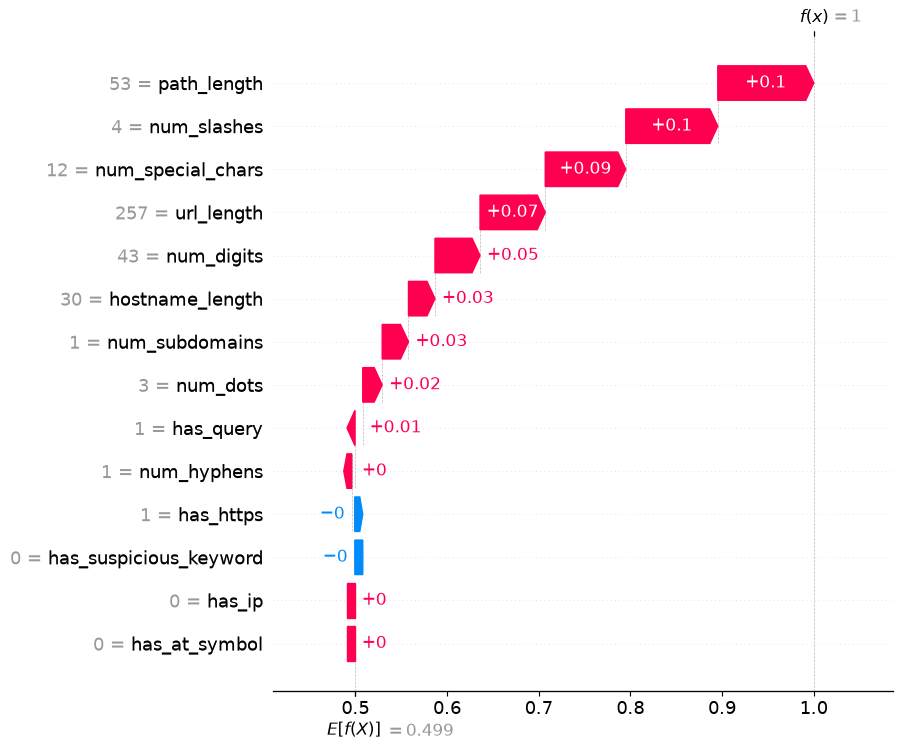

In [105]:
shap_explanation = shap.Explanation(
    values=shap_phish,
    base_values=base_phish,
    data=X_phish.iloc[0].values,
    feature_names=X_phish.columns.tolist()
)

shap.plots.waterfall(
    shap_explanation,
    max_display=14
)

In [106]:
import joblib
from pathlib import Path

# Create models directory
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save trained model
joblib.dump(
    model,
    models_dir / "phishing_rf_model.joblib"
)

# Save exact feature order
joblib.dump(
    X_train.columns.tolist(),
    models_dir / "feature_columns.joblib"
)

print("Model saved successfully!")
print("Feature columns saved successfully!")

print("\nModel:", models_dir / "phishing_rf_model.joblib")
print("Features:", models_dir / "feature_columns.joblib")

Model saved successfully!
Feature columns saved successfully!

Model: ..\models\phishing_rf_model.joblib
Features: ..\models\feature_columns.joblib


In [107]:
print(list(models_dir.iterdir()))

[WindowsPath('../models/feature_columns.joblib'), WindowsPath('../models/phishing_rf_model.joblib')]


In [108]:
import joblib

# Save SHAP explainer
joblib.dump(
    explainer,
    models_dir / "shap_explainer.joblib"
)

print("SHAP explainer saved!")

SHAP explainer saved!


In [109]:
print(list(models_dir.iterdir()))

[WindowsPath('../models/feature_columns.joblib'), WindowsPath('../models/phishing_rf_model.joblib'), WindowsPath('../models/shap_explainer.joblib')]


In [110]:
import joblib
import pandas as pd

# Load saved artifacts
model = joblib.load("../models/phishing_rf_model.joblib")
feature_columns = joblib.load("../models/feature_columns.joblib")
explainer = joblib.load("../models/shap_explainer.joblib")

print("Model loaded:", type(model))
print("Number of features:", len(feature_columns))
print("Feature columns:")
print(feature_columns)
print("SHAP explainer loaded:", type(explainer))

Model loaded: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Number of features: 14
Feature columns:
['url_length', 'hostname_length', 'path_length', 'num_dots', 'num_hyphens', 'num_slashes', 'num_digits', 'num_special_chars', 'has_https', 'has_at_symbol', 'has_query', 'has_ip', 'num_subdomains', 'has_suspicious_keyword']
SHAP explainer loaded: <class 'shap.explainers._tree.TreeExplainer'>


In [122]:
def predict_url(url):
    # -----------------------------
    # 1. Extract URL features
    # -----------------------------
    features = extract_url_features(url)

    X_new = pd.DataFrame([features])

    # Keep EXACTLY the same feature order used during training
    X_new = X_new[X.columns]

    # -----------------------------
    # 2. Model prediction
    # -----------------------------
    prediction = model.predict(X_new)[0]
    probabilities = model.predict_proba(X_new)[0]

    phishing_probability = probabilities[1]
    legitimate_probability = probabilities[0]

    label = "Phishing" if prediction == 1 else "Legitimate"

    # -----------------------------
    # 3. SHAP explanation
    # -----------------------------
    shap_values = url_explainer.shap_values(X_new)

    if isinstance(shap_values, list):

        shap_for_prediction = shap_values[prediction][0]
        base_value = url_explainer.expected_value[prediction]

    elif len(shap_values.shape) == 3:

        shap_for_prediction = shap_values[0, :, prediction]
        base_value = url_explainer.expected_value[prediction]

    else:

        shap_for_prediction = shap_values[0]
        base_value = url_explainer.expected_value

    # -----------------------------
    # 4. Create explanation table
    # -----------------------------
    explanation = pd.DataFrame({
        "feature": X_new.columns,
        "value": X_new.iloc[0].values,
        "shap_value": shap_for_prediction
    })

    explanation["abs_shap"] = explanation["shap_value"].abs()

    explanation = explanation.sort_values(
        "abs_shap",
        ascending=False
    )

    # -----------------------------
    # 5. Print result
    # -----------------------------
    print("URL:", url)
    print("Prediction:", label)
    print(f"Phishing probability: {phishing_probability:.2%}")
    print(f"Legitimate probability: {legitimate_probability:.2%}")

    print("\nTop contributing features:")
    print(
        explanation[
            ["feature", "value", "shap_value"]
        ].head(5).to_string(index=False)
    )

    # -----------------------------
    # 6. Return everything
    # -----------------------------
    return {
        "url": url,
        "prediction": int(prediction),
        "label": label,
        "phishing_probability": phishing_probability,
        "legitimate_probability": legitimate_probability,
        "features": X_new,
        "shap_values": shap_for_prediction,
        "base_value": base_value,
        "explanation": explanation
    }

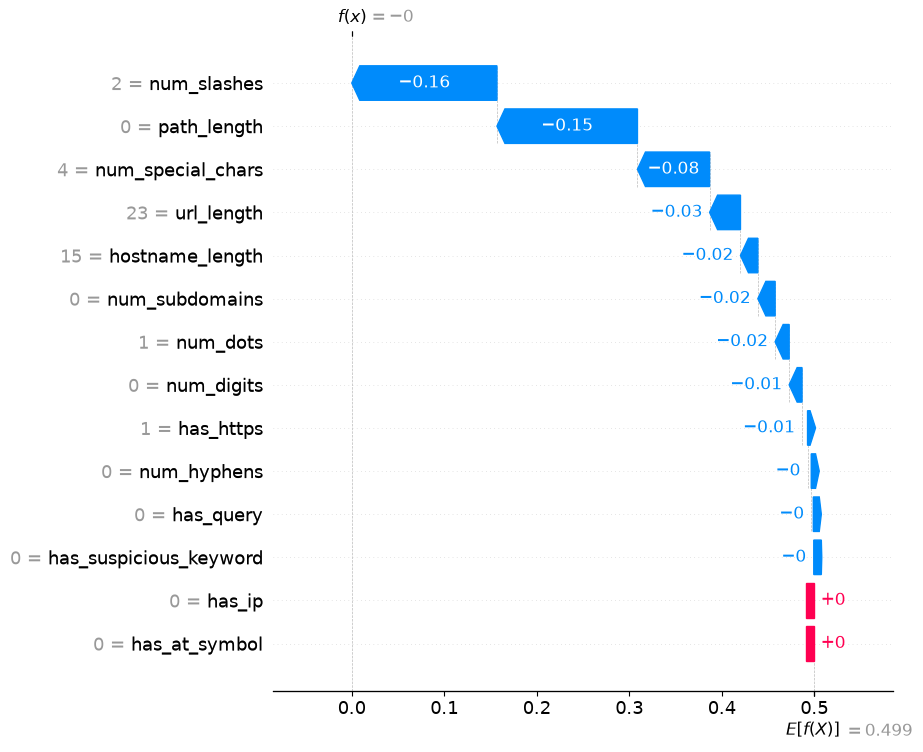

In [124]:
# Get the SHAP values for this URL
shap_values = explainer.shap_values(result["features"])

if isinstance(shap_values, list):
    shap_phish = shap_values[1][0]
else:
    shap_phish = shap_values[0, :, 1]

# Base value for phishing class
if isinstance(explainer.expected_value, list):
    base_phish = explainer.expected_value[1]
else:
    base_phish = explainer.expected_value[1]

# Create SHAP Explanation
shap_explanation = shap.Explanation(
    values=shap_phish,
    base_values=base_phish,
    data=result["features"].iloc[0].values,
    feature_names=result["features"].columns.tolist()
)

# Plot
shap.plots.waterfall(
    shap_explanation,
    max_display=14
)

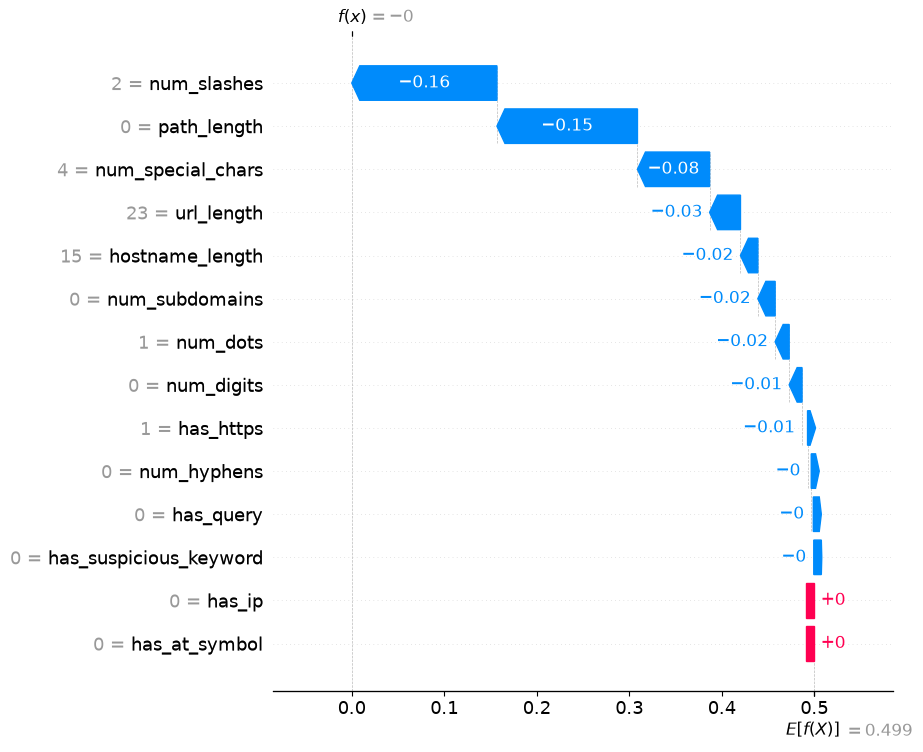

In [125]:
shap_explanation = shap.Explanation(
    values=shap_phish,
    base_values=base_phish,
    data=result["features"].iloc[0].values,
    feature_names=result["features"].columns.tolist()
)

shap.plots.waterfall(
    shap_explanation,
    max_display=14
)

In [126]:
def analyze_url(url):
    # =========================
    # 1. Extract features
    # =========================
    features = extract_url_features(url)

    X_new = pd.DataFrame([features])
    X_new = X_new[X.columns]

    # =========================
    # 2. Prediction
    # =========================
    prediction = model.predict(X_new)[0]
    probabilities = model.predict_proba(X_new)[0]

    phishing_probability = probabilities[1]
    legitimate_probability = probabilities[0]

    label = "Phishing" if prediction == 1 else "Legitimate"

    # =========================
    # 3. SHAP explanation
    # =========================
    shap_values = url_explainer.shap_values(X_new)

    if isinstance(shap_values, list):
        values = shap_values[prediction][0]
        base_value = url_explainer.expected_value[prediction]

    elif len(shap_values.shape) == 3:
        values = shap_values[0, :, prediction]
        base_value = url_explainer.expected_value[prediction]

    else:
        values = shap_values[0]
        base_value = url_explainer.expected_value

    # =========================
    # 4. Build explanation table
    # =========================
    explanation = pd.DataFrame({
        "feature": X_new.columns,
        "value": X_new.iloc[0].values,
        "shap_value": values
    })

    explanation["abs_shap"] = explanation["shap_value"].abs()

    explanation = explanation.sort_values(
        "abs_shap",
        ascending=False
    )

    top_features = explanation[
        ["feature", "value", "shap_value"]
    ].head(5)

    # =========================
    # 5. Print result
    # =========================
    print("URL:", url)
    print("Prediction:", label)
    print(f"Phishing probability: {phishing_probability:.2%}")
    print(f"Legitimate probability: {legitimate_probability:.2%}")

    print("\nTop contributing features:")
    print(top_features.to_string(index=False))

    # =========================
    # 6. Return everything
    # =========================
    return {
        "url": url,
        "prediction": int(prediction),
        "label": label,
        "phishing_probability": float(phishing_probability),
        "legitimate_probability": float(legitimate_probability),
        "features": X_new,
        "shap_values": values,
        "base_value": base_value,
        "explanation": top_features
    }

In [127]:
result = analyze_url("https://sourceready.com")

URL: https://sourceready.com
Prediction: Legitimate
Phishing probability: 0.00%
Legitimate probability: 100.00%

Top contributing features:
          feature  value  shap_value
      num_slashes      2    0.156913
      path_length      0    0.151869
num_special_chars      4    0.077961
       url_length     23    0.033382
  hostname_length     15    0.018781


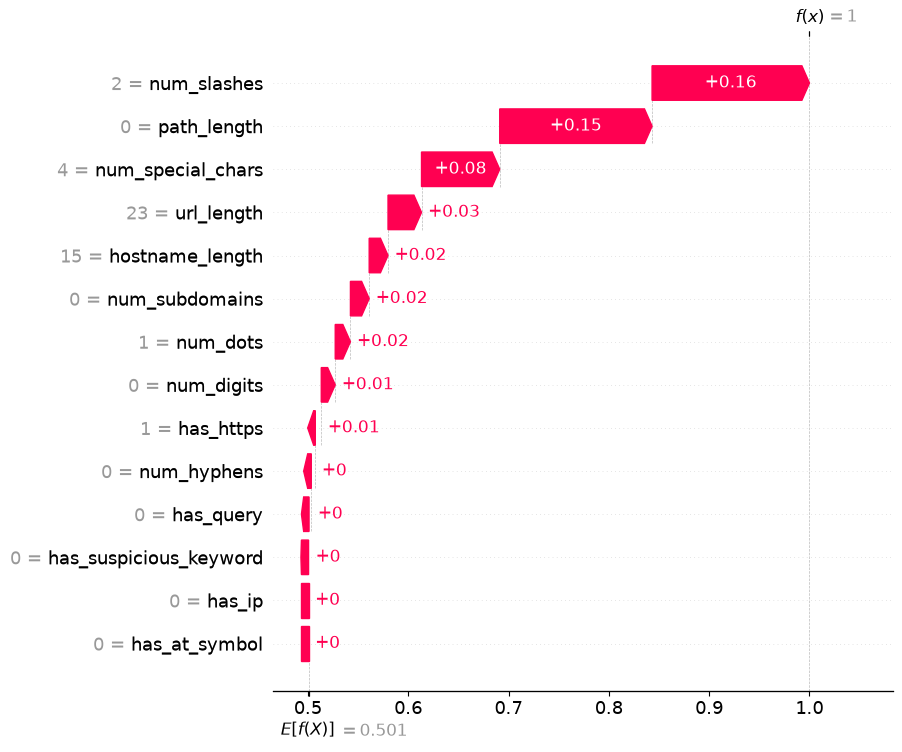

In [128]:
shap_explanation = shap.Explanation(
    values=result["shap_values"],
    base_values=result["base_value"],
    data=result["features"].iloc[0].values,
    feature_names=result["features"].columns.tolist()
)

shap.plots.waterfall(
    shap_explanation,
    max_display=14
)

In [132]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [133]:
from src.model import predict_url

result = predict_url("https://sourceready.com")

print(result)

{'url': 'https://sourceready.com', 'prediction': 'Legitimate', 'phishing_probability': 0.0, 'legitimate_probability': 1.0, 'features': {'url_length': 23, 'hostname_length': 15, 'path_length': 0, 'num_dots': 1, 'num_hyphens': 0, 'num_slashes': 2, 'num_digits': 0, 'num_special_chars': 4, 'has_https': 1, 'has_at_symbol': 0, 'has_query': 0, 'has_ip': 0, 'num_subdomains': 0, 'has_suspicious_keyword': 0}}
